# Soal 2 – Unsupervised Learning: DBSCAN
Epsilon (ε) = 1,2 ; MinPts = 2

Notebook ini mengerjakan 2b (perhitungan) dan 2c (plot). Gambar disimpan ke folder ``.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from matplotlib.patches import Circle


EPS, MINPTS = 1.2, 2
# Koordinat dibaca dari grafik soal (grid 0,5)
data = {'A':(1.5,1.0),'B':(1.0,2.5),'C':(3.0,0.5),'D':(3.5,1.5),'E':(3.0,1.0),
        'F':(0.5,3.0),'G':(1.5,3.5),'H':(2.0,3.0),'I':(2.5,2.0),'J':(4.0,4.0)}
df = pd.DataFrame(data, index=['x','y']).T
df

,x,y
A,1.5,1.0
B,1.0,2.5
C,3.0,0.5
D,3.5,1.5
E,3.0,1.0
F,0.5,3.0
G,1.5,3.5
H,2.0,3.0
I,2.5,2.0
J,4.0,4.0


## Gambar 1 – Data awal

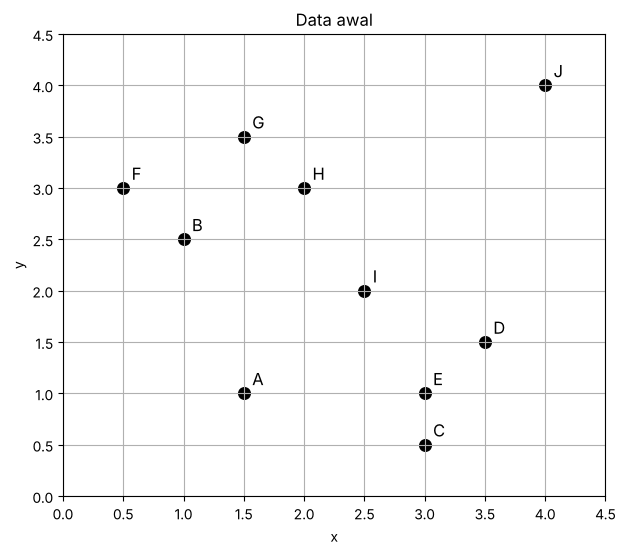

In [2]:
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(df.x, df.y, s=70, c='k')
for n,r in df.iterrows(): ax.annotate(n,(r.x,r.y),xytext=(6,6),textcoords='offset points',fontsize=12)
ax.set_xlim(0,4.5); ax.set_ylim(0,4.5); ax.set_xticks(np.arange(0,4.6,.5)); ax.set_yticks(np.arange(0,4.6,.5))
ax.grid(True); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('Data awal')
plt.savefig('gambar1_data_awal.png', dpi=200, bbox_inches='tight'); plt.show()

## Matriks jarak Euclidean

In [3]:
pts = df[['x','y']].values
D = np.sqrt(((pts[:,None,:]-pts[None,:,:])**2).sum(-1))
Ddf = pd.DataFrame(D, index=df.index, columns=df.index).round(3)
Ddf

,A,B,C,D,E,F,G,H,I,J
A,0.000,1.581,1.581,2.062,1.500,2.236,2.500,2.062,1.414,3.905
B,1.581,0.000,2.828,2.693,2.500,0.707,1.118,1.118,1.581,3.354
C,1.581,2.828,0.000,1.118,0.500,3.536,3.354,2.693,1.581,3.640
D,2.062,2.693,1.118,0.000,0.707,3.354,2.828,2.121,1.118,2.550
E,1.500,2.500,0.500,0.707,0.000,3.202,2.915,2.236,1.118,3.162
F,2.236,0.707,3.536,3.354,3.202,0.000,1.118,1.500,2.236,3.640
G,2.500,1.118,3.354,2.828,2.915,1.118,0.000,0.707,1.803,2.550
H,2.062,1.118,2.693,2.121,2.236,1.500,0.707,0.000,1.118,2.236
I,1.414,1.581,1.581,1.118,1.118,2.236,1.803,1.118,0.000,2.500
J,3.905,3.354,3.640,2.550,3.162,3.640,2.550,2.236,2.500,0.000


## Ε-neighborhood tiap titik (jarak ≤ ε, titik itu sendiri ikut dihitung)

In [4]:
names = list(df.index)
neigh = {n:[names[j] for j in range(len(names)) if D[i,j]<=EPS] for i,n in enumerate(names)}
rows=[]
for n in names:
    others=[m for m in neigh[n] if m!=n]
    rows.append({'Titik':n,'Tetangga (selain dirinya)':', '.join(others) or '-','|N_eps| (incl. diri)':len(neigh[n]),
                 'Core?':len(neigh[n])>=MINPTS})
pd.DataFrame(rows)

,Titik,Tetangga (selain dirinya),|N_eps| (incl. diri),Core?
0,A,-,1,False
1,B,"F, G, H",4,True
2,C,"D, E",3,True
3,D,"C, E, I",4,True
4,E,"C, D, I",4,True
5,F,"B, G",3,True
6,G,"B, F, H",4,True
7,H,"B, G, I",4,True
8,I,"D, E, H",4,True
9,J,-,1,False


## Proses DBSCAN manual

In [5]:
label = {n:None for n in names}   # None = belum dikunjungi, -1 = noise
core = {n: len(neigh[n])>=MINPTS for n in names}
cid = 0
for n in names:
    if label[n] is not None: continue
    if not core[n]:
        label[n] = -1; continue
    cid += 1; label[n] = cid
    queue = [m for m in neigh[n] if m!=n]
    while queue:
        q = queue.pop(0)
        if label[q] == -1: label[q] = cid          # noise -> border
        if label[q] is not None: continue
        label[q] = cid
        if core[q]: queue += [m for m in neigh[q] if label[m] is None or label[m]==-1]
    print(f'Klaster {cid} terbentuk dari {n}')
print(label)
df['label']=[label[n] for n in names]
df['status']=['Noise' if label[n]==-1 else ('Core' if core[n] else 'Border') for n in names]
df

Klaster 1 terbentuk dari B
{'A': -1, 'B': 1, 'C': 1, 'D': 1, 'E': 1, 'F': 1, 'G': 1, 'H': 1, 'I': 1, 'J': -1}


,x,y,label,status
A,1.5,1.0,-1,Noise
B,1.0,2.5,1,Core
C,3.0,0.5,1,Core
D,3.5,1.5,1,Core
E,3.0,1.0,1,Core
F,0.5,3.0,1,Core
G,1.5,3.5,1,Core
H,2.0,3.0,1,Core
I,2.5,2.0,1,Core
J,4.0,4.0,-1,Noise


## Verifikasi dengan scikit-learn

In [6]:
from sklearn.cluster import DBSCAN
sk = DBSCAN(eps=EPS, min_samples=MINPTS).fit(pts)
print('sklearn  :', dict(zip(names, sk.labels_)))
print('manual   :', dict(zip(names, df.label)))
print('Sama?    :', all((sk.labels_==-1)==(df.label.values==-1)))
print('Jumlah klaster:', len(set(sk.labels_))-(1 if -1 in sk.labels_ else 0), '| Outlier:', [n for n,l in zip(names,sk.labels_) if l==-1])

# Uji sensitivitas: MinPts = 2 tanpa menghitung diri sendiri (butuh 2 tetangga)
core2 = {n: (len(neigh[n])-1)>=2 for n in names}
print('Core jika MinPts tidak menghitung diri sendiri:', [n for n in names if core2[n]])

sklearn  : {'A': np.int64(-1), 'B': np.int64(0), 'C': np.int64(0), 'D': np.int64(0), 'E': np.int64(0), 'F': np.int64(0), 'G': np.int64(0), 'H': np.int64(0), 'I': np.int64(0), 'J': np.int64(-1)}
manual   : {'A': -1, 'B': 1, 'C': 1, 'D': 1, 'E': 1, 'F': 1, 'G': 1, 'H': 1, 'I': 1, 'J': -1}
Sama?    : True
Jumlah klaster: 1 | Outlier: ['A', 'J']
Core jika MinPts tidak menghitung diri sendiri: ['B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']


## Gambar 2 – Lingkaran ε dan graf ketetanggaan

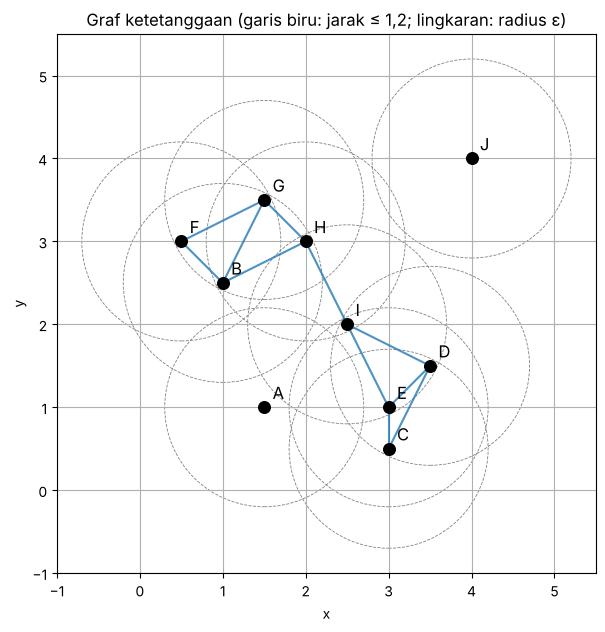

In [7]:
fig, ax = plt.subplots(figsize=(8,7))
for i,n in enumerate(names):
    for m in neigh[n]:
        if m>n: ax.plot([df.x[n],df.x[m]],[df.y[n],df.y[m]],'-',c='tab:blue',lw=1.5,alpha=.8)
for n in names: ax.add_patch(Circle((df.x[n],df.y[n]),EPS,fill=False,ls='--',lw=.6,ec='gray'))
ax.scatter(df.x, df.y, s=70, c='k', zorder=3)
for n,r in df.iterrows(): ax.annotate(n,(r.x,r.y),xytext=(6,6),textcoords='offset points',fontsize=12)
ax.set_xlim(-1,5.5); ax.set_ylim(-1,5.5); ax.set_aspect('equal'); ax.grid(True)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('Graf ketetanggaan (garis biru: jarak ≤ 1,2; lingkaran: radius ε)')
plt.savefig('gambar2_graf_ketetanggaan.png', dpi=200, bbox_inches='tight'); plt.show()

## Gambar 3 – Hasil klasterisasi (jawaban 2c)

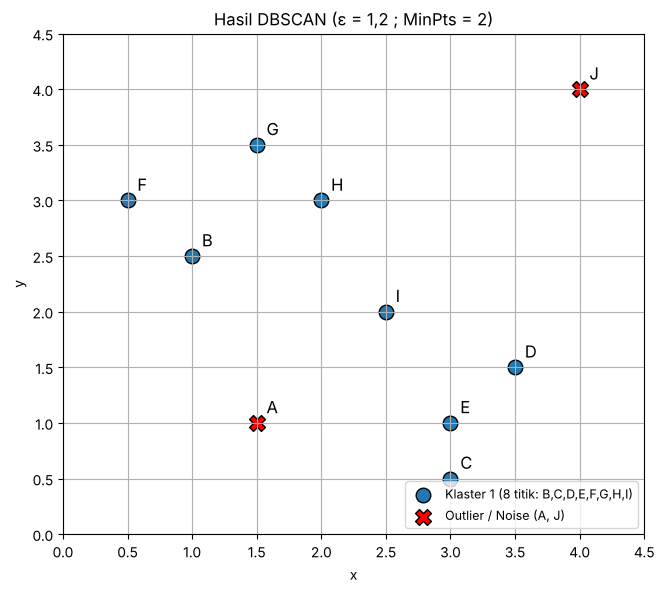

In [8]:
fig, ax = plt.subplots(figsize=(7.5,6.5))
cl = df[df.label!=-1]; no = df[df.label==-1]
ax.scatter(cl.x, cl.y, s=110, c='tab:blue', label='Klaster 1 (8 titik: B,C,D,E,F,G,H,I)', edgecolor='k')
ax.scatter(no.x, no.y, s=130, c='red', marker='X', label='Outlier / Noise (A, J)', edgecolor='k')
for n,r in df.iterrows(): ax.annotate(n,(r.x,r.y),xytext=(7,7),textcoords='offset points',fontsize=12)
ax.set_xlim(0,4.5); ax.set_ylim(0,4.5); ax.set_xticks(np.arange(0,4.6,.5)); ax.set_yticks(np.arange(0,4.6,.5))
ax.grid(True); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(loc='lower right', fontsize=9)
ax.set_title('Hasil DBSCAN (ε = 1,2 ; MinPts = 2)')
plt.savefig('gambar3_hasil_dbscan.png', dpi=200, bbox_inches='tight'); plt.show()

## Gambar 4 (opsional) – Perbandingan sensitivitas ε

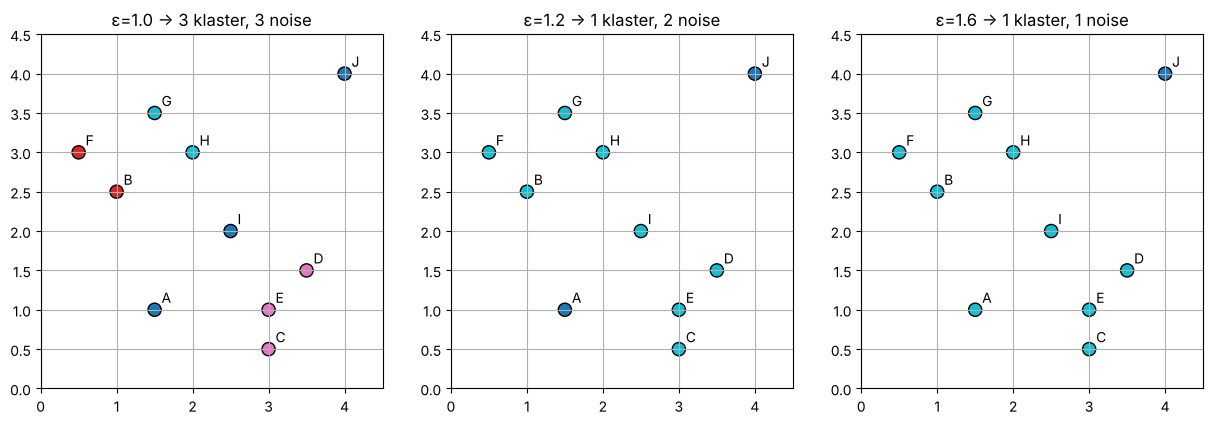

In [9]:
fig, axs = plt.subplots(1,3,figsize=(15,4.6))
for ax,e in zip(axs,[1.0,1.2,1.6]):
    l = DBSCAN(eps=e,min_samples=MINPTS).fit(pts).labels_
    ax.scatter(df.x,df.y,c=l,cmap='tab10',s=90,edgecolor='k')
    for n,r in df.iterrows(): ax.annotate(n,(r.x,r.y),xytext=(5,5),textcoords='offset points')
    k=len(set(l))-(1 if -1 in l else 0)
    ax.set_title(f'ε={e} → {k} klaster, {(l==-1).sum()} noise'); ax.grid(True)
    ax.set_xlim(0,4.5); ax.set_ylim(0,4.5)
plt.savefig('gambar4_sensitivitas_eps.png', dpi=200, bbox_inches='tight'); plt.show()